<a href="https://colab.research.google.com/github/PriyankaAntony/qsar-fish-toxicity-ml/blob/main/Welcome_to_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [104]:
import pandas as pd

df = pd.read_excel("qsar_fish_toxicity.xlsx", header=None)
if df.iloc[0].apply(lambda v: isinstance(v, str)).any():  # drop a header row if there is one
    df = df.iloc[1:].reset_index(drop=True)
df = df.astype(float)
print(df.shape)  # should print (908, 7)
print(df.head())
df.to_csv("qsar_fish_toxicity.csv", sep=";", header=False, index=False)

(908, 7)
       0      1      2    3    4      5      6
0  3.260  0.829  1.676  0.0  1.0  1.453  3.770
1  2.189  0.580  0.863  0.0  0.0  1.348  3.115
2  2.125  0.638  0.831  0.0  0.0  1.348  3.531
3  3.027  0.331  1.472  1.0  0.0  1.807  3.510
4  2.094  0.827  0.860  0.0  0.0  1.886  5.390


In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

DATA_FILE = "qsar_fish_toxicity.csv"
LOG_RESPONSE = False   # True = model log(LC50); metrics are reported on the LC50 scale
SEED = 42

cols = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]
df = pd.read_csv(DATA_FILE, sep=";", header=None, names=cols)

# 1. Exploratory data analysis
print(df.shape)
print(df.describe())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))

(908, 7)
             CIC0      SM1_Dz      GATS1i       NdsCH       NdssC       MLOGP  \
count  908.000000  908.000000  908.000000  908.000000  908.000000  908.000000   
mean     2.898129    0.628468    1.293591    0.229075    0.485683    2.109285   
std      0.756088    0.428459    0.394303    0.605335    0.861279    1.433181   
min      0.667000    0.000000    0.396000    0.000000    0.000000   -2.884000   
25%      2.347000    0.223000    0.950750    0.000000    0.000000    1.209000   
50%      2.934000    0.570000    1.240500    0.000000    0.000000    2.127000   
75%      3.407000    0.892750    1.562250    0.000000    1.000000    3.105000   
max      5.926000    2.171000    2.920000    4.000000    6.000000    6.515000   

             LC50  
count  908.000000  
mean     4.064431  
std      1.455698  
min      0.053000  
25%      3.151750  
50%      3.987500  
75%      4.907500  
max      9.612000  
Missing values: 0
Duplicated rows: 1


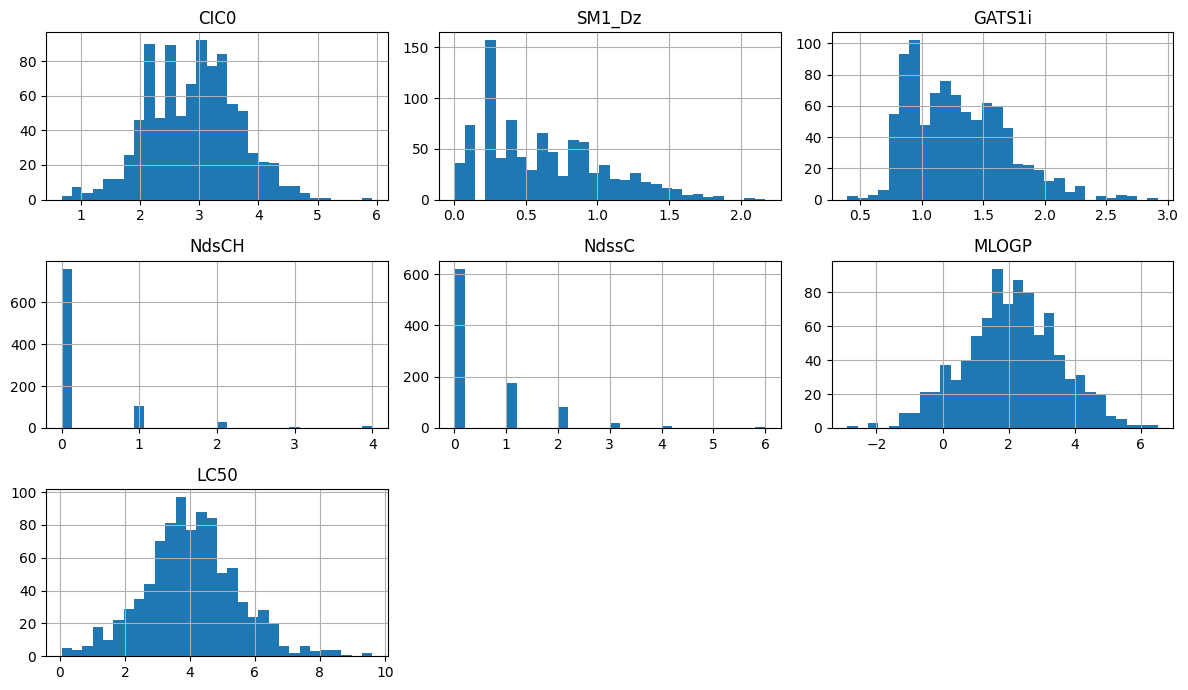

In [106]:
df.hist(figsize=(12, 7), bins=30)
plt.tight_layout()
plt.savefig("histograms.png")
plt.show()

In [107]:
# 2. Outlier removal (boxplot / IQR rule, one pass over all columns)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outlier = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).any(axis=1)
df_clean = df[~outlier].copy()
print("Rows before:", len(df), " after outlier removal:", len(df_clean))

Rows before: 908  after outlier removal: 710


        CIC0  SM1_Dz  GATS1i  NdsCH  NdssC  MLOGP  LC50
CIC0    1.00   -0.28    0.20    NaN   0.14   0.40  0.25
SM1_Dz -0.28    1.00   -0.16    NaN   0.10   0.20  0.45
GATS1i  0.20   -0.16    1.00    NaN   0.13  -0.43 -0.41
NdsCH    NaN     NaN     NaN    NaN    NaN    NaN   NaN
NdssC   0.14    0.10    0.13    NaN   1.00  -0.09 -0.00
MLOGP   0.40    0.20   -0.43    NaN  -0.09   1.00  0.70
LC50    0.25    0.45   -0.41    NaN  -0.00   0.70  1.00


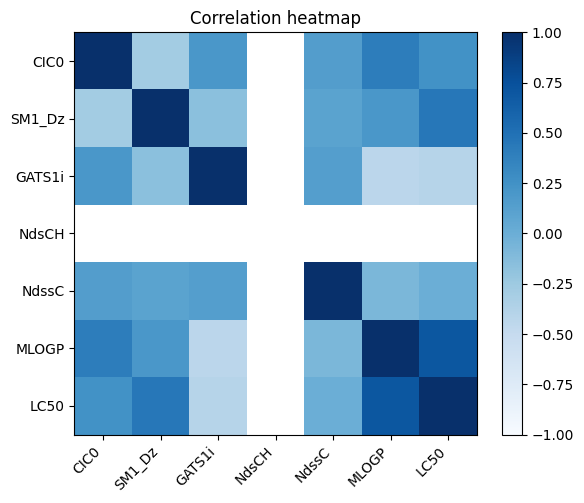

In [108]:
# 3. Correlation analysis
corr = df_clean.corr()
print(corr.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
fig.colorbar(im)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

In [109]:
# 4. Train/test split (85 : 15)
X = df_clean.drop(columns="LC50")
y = df_clean["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)


In [110]:
# 5. Linear regression
model = LinearRegression()
model.fit(X_train, np.log(y_train) if LOG_RESPONSE else y_train)
print(dict(zip(X.columns, model.coef_.round(3))), "intercept:", round(model.intercept_, 3))


{'CIC0': np.float64(0.393), 'SM1_Dz': np.float64(1.181), 'GATS1i': np.float64(-0.67), 'NdsCH': np.float64(0.0), 'NdssC': np.float64(-0.027), 'MLOGP': np.float64(0.441)} intercept: 1.968


In [111]:
def predict_lc50(features):
    pred = model.predict(features)
    return np.exp(pred) if LOG_RESPONSE else pred

In [112]:
# 6. Evaluation on training AND test data
pred_train, pred_test = predict_lc50(X_train), predict_lc50(X_test)
results = pd.DataFrame({
    "set": ["train", "test"],
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "RMSE": [np.sqrt(mean_squared_error(y_train, pred_train)),
             np.sqrt(mean_squared_error(y_test, pred_test))],
})
print(results.round(3))

     set     R2   RMSE
0  train  0.608  0.814
1   test  0.659  0.793


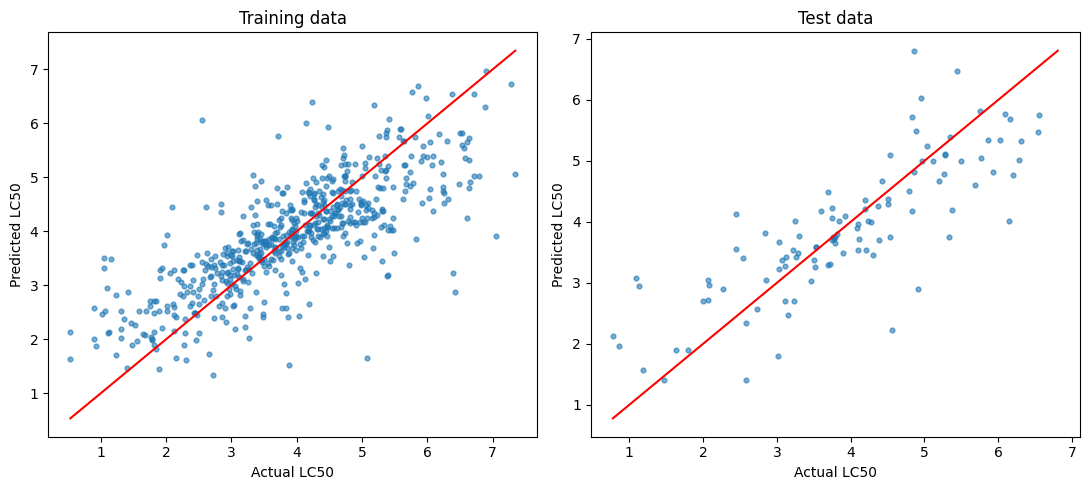

In [113]:
# 7. Actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, actual, pred, title in [(axes[0], y_train, pred_train, "Training data"),
                                (axes[1], y_test, pred_test, "Test data")]:
    ax.scatter(actual, pred, s=12, alpha=0.6)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    ax.plot(lims, lims, color="red")
    ax.set_xlabel("Actual LC50")
    ax.set_ylabel("Predicted LC50")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or ‘Colaboratory’, allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a <strong>student</strong>, a <strong>data scientist</strong> or an <strong>AI researcher</strong>, Colab can make your work easier. Watch <a href="https://www.youtube.com/watch?v=inN8seMm7UI">Introduction to Colab</a> or <a href="https://www.youtube.com/watch?v=rNgswRZ2C1Y">Colab features you may have missed</a> to learn more or just get started below!

<div class="markdown-google-sans">

## <strong>Getting started</strong>
</div>

The document that you are reading is not a static web page, but an interactive environment called a <strong>Colab notebook</strong> that lets you write and execute code.

For example, here is a <strong>code cell</strong> with a short Python script that computes a value, stores it in a variable and prints the result:

In [114]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut 'Command/Ctrl+Enter'. To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [115]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine <strong>executable code</strong> and <strong>rich text</strong> in a single document, along with <strong>images</strong>, <strong>HTML</strong>, <strong>LaTeX</strong> and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To find out more, see <a href="/notebooks/basic_features_overview.ipynb">Overview of Colab</a>. To create a new Colab notebook you can use the File menu above, or use the following link: <a href="http://colab.research.google.com#create=true">Create a new Colab notebook</a>.

Colab notebooks are Jupyter notebooks that are hosted by Colab. To find out more about the Jupyter project, see <a href="https://www.jupyter.org">jupyter.org</a>.

## Google Colab is available in VS Code!
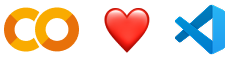

Try the new <a href="https://marketplace.visualstudio.com/items?itemName=Google.colab">Google Colab extension</a> for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the <strong><em>Extensions</em></strong> view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any <code>.ipynb</code> notebook file in your local workspace and either running a cell or clicking the <strong><em>Select kernel</em></strong> button in the top right.
*  Click <strong><em>Colab</em></strong> and then select your desired runtime, sign in with your Google Account and you're all set!

See more details in our <a href="https://developers.googleblog.com/google-colab-is-coming-to-vs-code">announcement blog here</a>.

## Access popular AI models via Google Colab-AI without an API key
All users have access to most popular LLMs via the <code>google-colab-ai</code> Python library, and paid users have access to a wider selection of models. For more details, refer to <a href="https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb">getting started with Google Colab AI</a>.



In [116]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code and audio.

**How to get started**
*  Go to <a href="https://aistudio.google.com/">Google AI Studio</a> and log in with your Google Account.
*  <a href="https://aistudio.google.com/app/apikey">Create an API key</a>.
* Use a quickstart for <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb">Python</a> or call the REST API using <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb">curl</a>.

**Discover Gemini's advanced capabilities**
*  Play with Gemini <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb">multimodal outputs</a>, mixing text and images in an iterative way.
*  Discover the <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb">multimodal Live API</a> &#40;demo <a href="https://aistudio.google.com/live">here</a>&#41;.
*  Learn how to <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb&quot;">analyse images and detect items in your pictures</a> using Gemini &#40;bonus, there's a <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb">3D version</a> as well!&#41;.
*  Unlock the power of the <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb">Gemini thinking model</a>, capable of solving complex tasks with its inner thoughts.
      
**Explore complex use cases**
*  Use <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb">Gemini grounding capabilities</a> to create a report on a company based on what the model can find on the Internet.
*  Extract <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb">invoices and form data from PDFs</a> in a structured way.
*  Create <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb">illustrations based on a whole book</a> using Gemini large context window and Imagen.

To learn more, take a look at the <a href="https://github.com/google-gemini/cookbook">Gemini cookbook</a> or visit the <a href="https://ai.google.dev/docs/">Gemini API documentation</a>.


Colab now has AI features powered by <a href="https://gemini.google.com">Gemini</a>. The video below provides information on how to use these features, whether you're new to Python or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  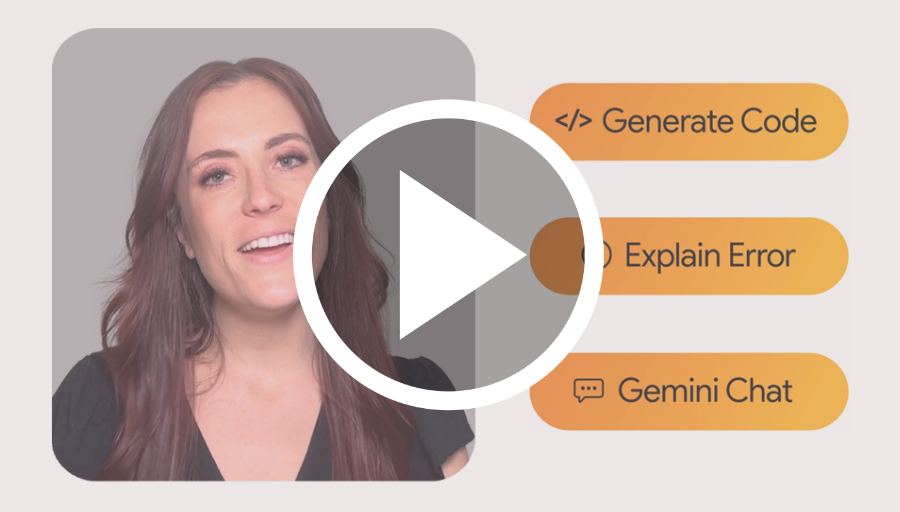
  </a>
</center>

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyse and visualise data. The code cell below uses <strong>numpy</strong> to generate some random data, and uses <strong>matplotlib</strong> to visualise it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from GitHub and many other sources. To find out more about importing data, and how Colab can be used for data science, see the links below under <a href="#working-with-data">Working with data</a>.

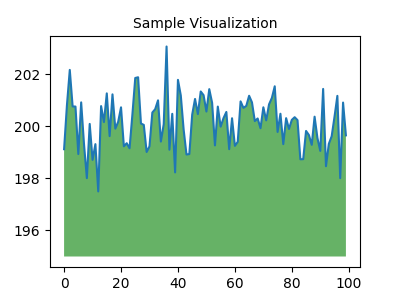

In [117]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning that you can leverage the power of Google hardware, including <a href="#using-accelerated-hardware">GPUs and TPUs</a>, regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for <strong>pandas</strong> code to finish running and want to go faster, you can switch to a GPU runtime and use libraries like <a href="https://rapids.ai/cudf-pandas">RAPIDS cuDF</a> that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb">10-minute guide</a> or
 <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb">US stock market data analysis demo</a>.

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it and evaluate the model, all in just <a href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb">a few lines of code</a>.

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the <a href="#machine-learning-examples">machine learning examples</a> below.

<div class="markdown-google-sans">

## More resources

### Working with notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with data
</div>

- [Loading data: Drive, Sheets and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualising data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine learning

<div>

These are a few of the notebooks related to machine learning, including Google's online machine learning course. See the <a href="https://developers.google.com/machine-learning/crash-course/">full course website</a> for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using accelerated hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer &#40;ViT&#41; for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- <a href="https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html">Train a miniGPT language model with JAX AI stack</a>
- <a href="https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb">LoRA/QLoRA finetuning for LLM using Tunix</a>
- <a href="https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/">Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA</a>
- <a href="https://keras.io/keras_hub/guides/hugging_face_keras_integration/">Loading Hugging Face transformers checkpoints</a>
- <a href="https://keras.io/guides/int8_quantization_in_keras/">8-bit integer quantisation in Keras</a>
- <a href="https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/">Float8 training and inference with a simple transformer model</a>
- <a href="https://keras.io/keras_hub/guides/transformer_pretraining/">Pretraining a transformer from scratch with KerasHub</a>
- <a href="https://keras.io/examples/vision/mnist_convnet/">Simple MNIST convnet</a>
- <a href="https://keras.io/examples/vision/image_classification_from_scratch/">Image classification from scratch using Keras 3</a>
- <a href="https://keras.io/keras_hub/guides/classification_with_keras_hub/">Image classification with KerasHub</a>
